In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.cluster import DBSCAN
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

In [2]:
X, y = make_blobs(
    n_samples=[200, 200, 200],
    centers=[(-5, -2), (0, 0), (5, 4)],
    cluster_std=[0.4, 0.8, 1.5],
    random_state=42
)

In [3]:
rng = np.random.RandomState(42)
noise = rng.uniform(-10, 10, size=(50, 2))
X = np.vstack([X, noise])

In [4]:
X = StandardScaler().fit_transform(X)

In [5]:
model = DBSCAN(eps=0.3, min_samples=5)
labels = model.fit_predict(X)

In [6]:
n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
n_noise = np.sum(labels == -1)

In [7]:
print("Number of clusters:", n_clusters)
print("Number of noise points:", n_noise)

Number of clusters: 2
Number of noise points: 43


In [8]:
mask = labels != -1

if len(set(labels[mask])) > 1:
    score = silhouette_score(X[mask], labels[mask])
    print("Silhouette Score:", score)
else:
    print("Silhouette Score: Not defined")

Silhouette Score: 0.5376759261935595


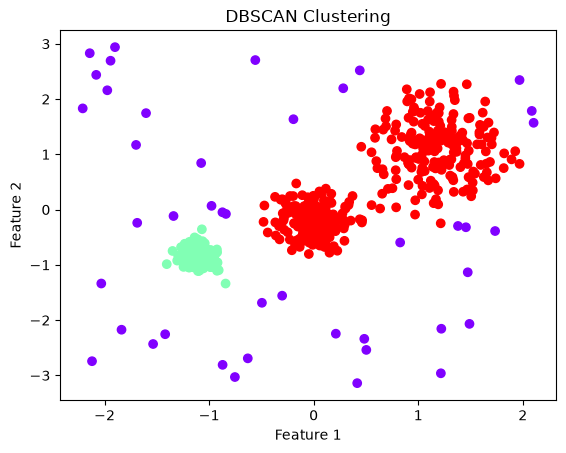

In [9]:
plt.scatter(X[:, 0], X[:, 1], c=labels, cmap='rainbow')
plt.title("DBSCAN Clustering")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()